# Figs 1–2: composition and UMAP

Contract: `audit/contracts/F12_figures.md`. Plot and UMAP code lives in `src/figures.py`.
Input: `data/processed/m0_cells.h5ad` (all 24,562 cells; outliers kept). UMAP recipe C2, no integration (C1).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
from IPython.display import display

from src import figures

N_CELLS = 24562
(ROOT / "figures").mkdir(exist_ok=True)
adata = ad.read_h5ad(ROOT / "data/processed/m0_cells.h5ad")
assert adata.n_obs == N_CELLS, adata.n_obs
print(adata)

AnnData object with n_obs × n_vars = 24562 × 15701
    obs: 'barcode', 'condition', 'donor', 'cell_type', 'cluster', 'tsne1', 'tsne2', 'n_counts', 'n_genes', 'pct_ribo', 'flag_outlier', 'flag_small_group', 'flag_underpowered_celltype'
    var: 'name', 'n_cells'
    uns: 'control', 'treatment'
    obsm: 'X_pca', 'X_umap'


## Fig 1: cells per donor, condition and cell type

PASS: Fig 1 bar totals equal data_facts.md for all 16 donor × condition bars; sum = 24562


cell_type               B cells  CD14+ Monocytes  CD4 T cells  CD8 T cells  \
donor        condition                                                       
patient_1039 ctrl            26              112          182           26   
             stim            39              150          272           29   
patient_107  ctrl            44              209          158           20   
             stim            54              169          186           15   
patient_101  ctrl           107              202          293           74   
             stim           135              253          382          105   
patient_1016 ctrl           126              369          422          536   
             stim           116              329          353          489   
patient_1244 ctrl           116              415         1068           58   
             stim            93              290          854           32   
patient_1256 ctrl           216              390         1001          131   
             stim           208              375          954          112   
patient_1488 ctrl           218              294         1182           58   
             stim           279              348         1484           43   
patient_1015 ctrl           453              779          848          179   
             stim           341              671          734          133   

cell_type               Dendritic cells  FCGR3A+ Monocytes  Megakaryocytes  \
donor        condition                                                       
patient_1039 ctrl                     9                 31               4   
             stim                    17                 43              11   
patient_107  ctrl                     8                 32               6   
             stim                    14                 37               4   
patient_101  ctrl                    21                 80              11   
             stim                    34                144               9   
patient_1016 ctrl                    19                115               8   
             stim                    15                128              10   
patient_1244 ctrl                    47                 56              14   
             stim                    33                 35              13   
patient_1256 ctrl                    26                 69              14   
             stim                    32                 97              17   
patient_1488 ctrl                    43                101              18   
             stim                    54                144              29   
patient_1015 ctrl                    30                252              20   
             stim                    30                228              20   

cell_type               NK cells  total  
donor        condition                   
patient_1039 ctrl             18    408  
             stim             23    584  
patient_107  ctrl             40    517  
             stim             46    525  
patient_101  ctrl             70    858  
             stim            104   1166  
patient_1016 ctrl            128   1723  
             stim            195   1635  
patient_1244 ctrl            105   1879  
             stim            114   1464  
patient_1256 ctrl            261   2108  
             stim            231   2026  
patient_1488 ctrl            116   2030  
             stim            168   2549  
patient_1015 ctrl            177   2738  
             stim            195   2352

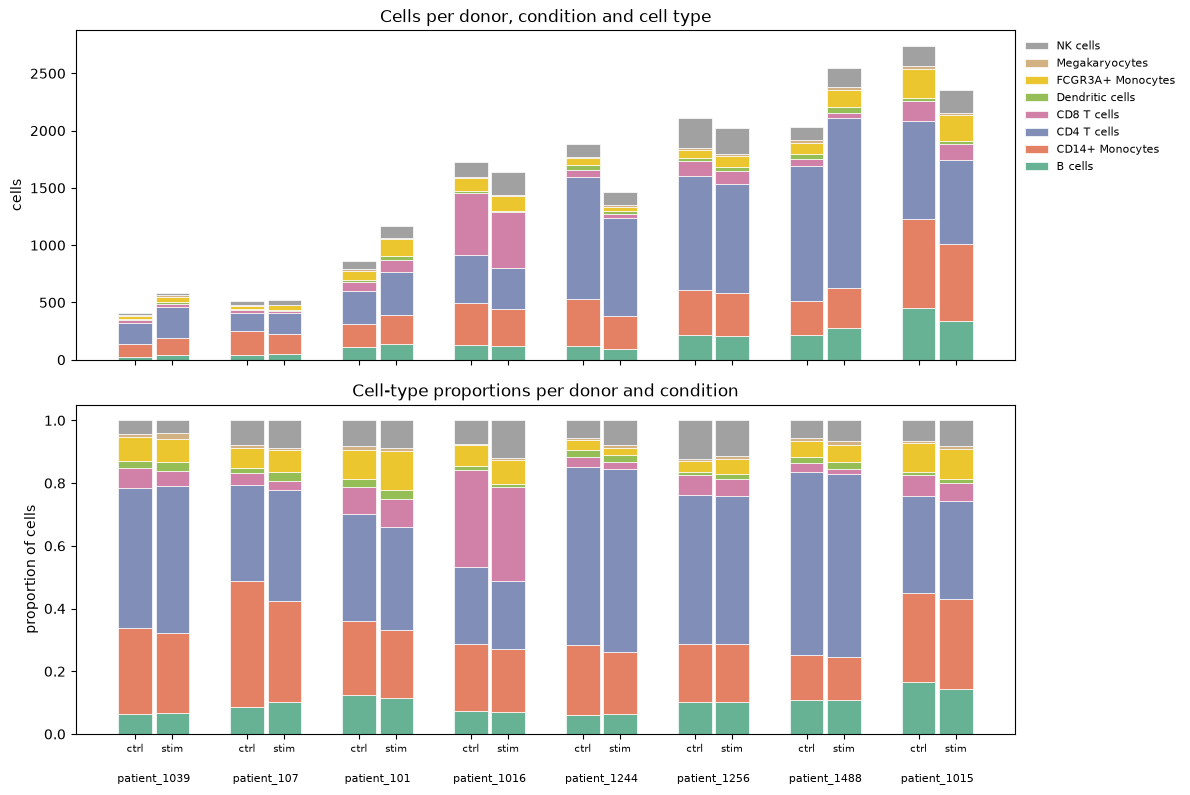

In [2]:
counts = figures.composition_counts(adata.obs)

# Expected cells per donor × condition: the table in audit/data_facts.md
lines = (ROOT / "audit/data_facts.md").read_text().split("## Cells per donor × condition")[1].split("##")[0].strip().splitlines()
rows = [[c.strip() for c in l.strip("|").split("|")] for l in lines if l.startswith("| patient_")]
facts = pd.DataFrame(rows, columns=["donor", "ctrl", "stim", "total"]).set_index("donor").astype(int)
expected = facts[["ctrl", "stim"]].stack().rename_axis(["donor", "condition"])
bar_totals = counts.sum(axis=1)
assert (bar_totals.values == expected.loc[bar_totals.index].values).all() and len(expected) == len(bar_totals) == 16
assert bar_totals.sum() == N_CELLS
print("PASS: Fig 1 bar totals equal data_facts.md for all 16 donor × condition bars; sum =", bar_totals.sum())

fig1 = figures.plot_fig1(counts)
for ext in ("png", "pdf"):
    fig1.savefig(ROOT / f"figures/fig1_composition.{ext}", dpi=200, bbox_inches="tight")
display(counts.assign(total=bar_totals))

## Fig 2: UMAP (C2 recipe, no integration)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


/Users/prakritipaul/anaconda3/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


/Users/prakritipaul/Git/IFNbeta-immune-celltype-txn-effects/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PASS I3: both panels draw the same 24562 cells at identical coordinates


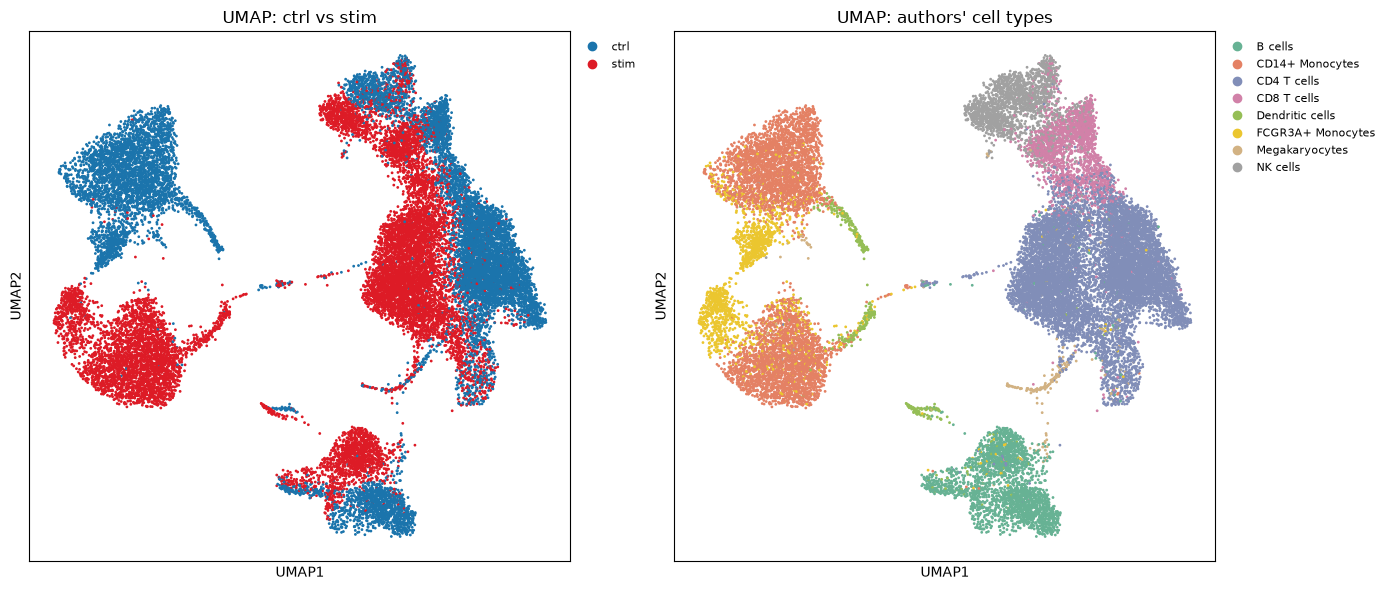

In [3]:
emb = figures.compute_umap(adata)
df = adata.obs[["barcode", "condition", "cell_type"]].join(emb)
assert len(df) == N_CELLS and df.index.equals(adata.obs_names)
assert np.isfinite(df[["umap1", "umap2"]].to_numpy()).all()

fig2 = figures.plot_fig2(df)
# I3: both panels plot the same cells at identical coordinates
off = [ax.collections[0].get_offsets() for ax in fig2.axes]
assert off[0].shape == off[1].shape == (N_CELLS, 2)
assert np.array_equal(np.asarray(off[0]), np.asarray(off[1]))
assert np.array_equal(np.sort(np.asarray(off[0]), axis=0), np.sort(df[["umap1", "umap2"]].to_numpy(), axis=0))
print(f"PASS I3: both panels draw the same {N_CELLS} cells at identical coordinates")
for ext in ("png", "pdf"):
    fig2.savefig(ROOT / f"figures/fig2_umap.{ext}", dpi=200, bbox_inches="tight")

In [4]:
out = df[["barcode", "condition", "umap1", "umap2"]]
out.to_csv(ROOT / "data/processed/f2_umap.csv", index=False)
back = pd.read_csv(ROOT / "data/processed/f2_umap.csv")
assert back.shape == (N_CELLS, 4) and back["barcode"].is_unique
print("f2_umap.csv shape:", back.shape)
display(back.head()); display(back.tail())

f2_umap.csv shape: (24562, 4)


,barcode,condition,umap1,umap2
0,AAACATACATTTCC-1,ctrl,-1.114449,10.241630
1,AAACATACCAGAAA-1,ctrl,-1.115222,14.148938
2,AAACATACCATGCA-1,ctrl,12.869485,2.294503
3,AAACATACCTCGCT-1,ctrl,-1.133072,10.955972
4,AAACATACCTGGTA-1,ctrl,5.224737,0.734459


,barcode,condition,umap1,umap2
24557,TTTGCATGCCTGAA-2,stim,10.357009,9.207578
24558,TTTGCATGCCTGTC-2,stim,7.320263,-2.926967
24559,TTTGCATGCTAAGC-2,stim,9.356835,6.850413
24560,TTTGCATGGGACGA-2,stim,9.117835,7.425764
24561,TTTGCATGTCTTAC-2,stim,11.114378,9.225468
